In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

In [3]:
case_test = pd.read_csv('data/csv/calc_case_description_test_set.csv')
case_train = pd.read_csv('data/csv/calc_case_description_train_set.csv')
mass_test = pd.read_csv('data/csv/mass_case_description_test_set.csv')
mass_train = pd.read_csv('data/csv/mass_case_description_train_set.csv')

In [ ]:
case_test.head()

In [ ]:
case_train.head()

In [ ]:
mass_test.head()

In [ ]:
mass_train.head()

## Working only with 'case' for this template. Duplicate for 'mass'

In [8]:
# list all columns
print(case_train.columns)

# print unique values of pathology 
print(case_train['pathology'].unique())

Index(['patient_id', 'breast density', 'left or right breast', 'image view',
       'abnormality id', 'abnormality type', 'calc type', 'calc distribution',
       'assessment', 'pathology', 'subtlety', 'image file path',
       'cropped image file path', 'ROI mask file path'],
      dtype='object')
['MALIGNANT' 'BENIGN' 'BENIGN_WITHOUT_CALLBACK']


In [9]:
# choose features for your model
features = ['breast density', 'left or right breast', 'image view',
       'abnormality id', 'abnormality type', 'calc type', 'calc distribution',
       'assessment', 'subtlety']
X_train = case_train[features]

# we are trying to predict pathology
y_train = case_train["pathology"]

# assigning the same things to the test dataset
X_test = case_test[features]
y_test = case_test['pathology']

In [10]:
# combine datasets
X = pd.concat([X_train, X_test], ignore_index=True)
y = pd.concat([y_train, y_test], ignore_index=True)

In [ ]:
# normalize features, meaning adjust numeric values of diff data into a similar scale. necessary so each thing can be weighed similarly
scaler = StandardScaler()

# NOTE!! THIS WILL ERROR BECAUSE WE HAVE CATEGORICAL DATA
# we need to convert all categorical data into numeric values
# if we convert to numeric values, then we have an inherent "ordering" of the values
# therefore, we need to use a distance metric that accounts for categorical values
X_scaled = scaler.fit_transform(X)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Note! Since our dataset already splits it into training and testing, we don't need to do that on our own. This is important to be aware of, because there is a function in sklearn that can split our data into training and testing and you'll often see code online use that

Documentation: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html

In [ ]:
# Train a k-NN classifier
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

In [ ]:
# Predict and evaluate
y_pred = knn.predict(X_test)
print(f"Test Accuracy (k=5): {accuracy_score(y_test, y_pred):.2f}")

To see how well this does, let's run cross-validation. 

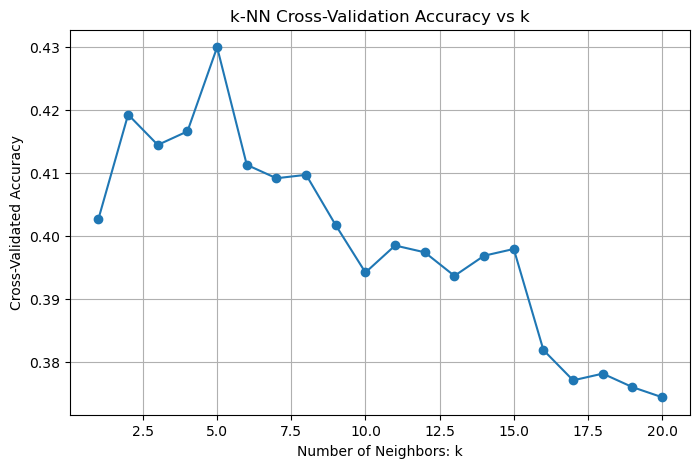

Best k from cross-validation: 5


In [ ]:
# for cross validation, we use the training data

# Range of k values to try
k_range = range(1, 21)
cv_scores = []

# Evaluate each k using 5-fold cross-validation
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

# Plot accuracy vs. k
plt.figure(figsize=(8, 5))
plt.plot(k_range, cv_scores, marker='o')
plt.title("k-NN Cross-Validation Accuracy vs k")
plt.xlabel("Number of Neighbors: k")
plt.ylabel("Cross-Validated Accuracy")
plt.grid(True)
plt.show()

# Best k
best_k = k_range[np.argmax(cv_scores)]
print(f"Best k from cross-validation: {best_k}")

Confusion Matrix

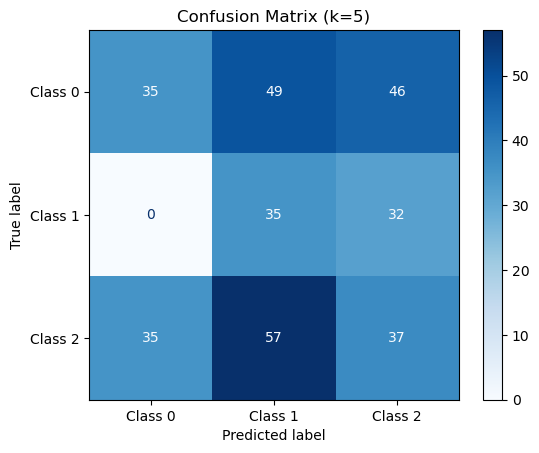

Classification Report:
              precision    recall  f1-score   support

     Class 0       0.50      0.27      0.35       130
     Class 1       0.25      0.52      0.34        67
     Class 3       0.32      0.29      0.30       129

    accuracy                           0.33       326
   macro avg       0.36      0.36      0.33       326
weighted avg       0.38      0.33      0.33       326



In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Class 0", "Class 1", "Class 2"])
disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix (k={best_k})")
plt.grid(False)
plt.show()

# Detailed classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Class 0", "Class 1", "Class 3"]))





hi

# Kenneth's Section

## Setting Up Process

Reading CSV (Sorry I changed case to calc)

In [2]:
calc_test = pd.read_csv('data/csv/calc_case_description_test_set.csv')
calc_train = pd.read_csv('data/csv/calc_case_description_train_set.csv')
mass_test = pd.read_csv('data/csv/mass_case_description_test_set.csv')
mass_train = pd.read_csv('data/csv/mass_case_description_train_set.csv')

Choosing Features: (FEATURES CAN BE ADJUSTED)

In [ ]:
features = ['breast density', 'left or right breast', 'image view',
       'abnormality id', 'abnormality type', 'calc type', 'calc distribution',
       'assessment', 'subtlety']
X_train = calc_train[features]                   #Data Frame

y_train = calc_train["pathology"]                #Panda Series

X_test = calc_test[features]
y_test = calc_test['pathology']

#Ultimately not needed...?
X = pd.concat([X_train, X_test])                 #Combining Data
y = (pd.concat([y_train, y_test])).to_frame()


Preprocessing (Converting categorical to encoded integers)   & Scaling


In [53]:
#ENCODING
enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

# X_encoded = enc.fit_transform(X)

X_train_encoded = enc.fit_transform(X_train)
X_test_encoded = enc.transform(X_test)


#SCALING
scaler = StandardScaler()

# X_scaled = scaler.fit_transform(X_encoded)           

X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

### Training   & Prediction

In [86]:
knn = KNeighborsClassifier(n_neighbors=4)           #Maybe try Manhattan Distance some other time?
knn.fit(X_train_scaled, y_train)


y_pred = knn.predict(X_test_scaled)
print(f"Test Accuracy (k=4): {accuracy_score(y_test, y_pred):.2f}")

Test Accuracy (k=4): 0.75


### Evaluation (Confusion Matrix and Cross Validation)

In [ ]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign", 
                                                                   "Benign_Without_Callback", 
                                                                   "Malignant"])
disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix (k=5)")
plt.grid(False)

# Detailed classification report
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=["Benign", 
                                                          "Benign_Without_Callback", 
                                                          "Malignant"]))

#Cross Validation
k_range = range(1,21)
cv_scores = []
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=skf, scoring='accuracy')
    cv_scores.append(scores.mean())

plt.figure(figsize=(8,5))
plt.plot(k_range, cv_scores, marker='o')
plt.title("k-NN Cross-Validation Accuracy vs k")
plt.xlabel("k Nearest Neighbors")
plt.ylabel("Cross Validation Accuracy")
plt.grid(True)
plt.show()

best_k = k_range[np.argmax(cv_scores)]
print(f"Best k from cross-validation: {best_k}")

## Putting it all Together

### Function

In [17]:
def run_KNN(train_file, test_file, plot_cm=False, plot_cv=False):
    train_data = pd.read_csv(f"{train_file}")
    test_data = pd.read_csv(f"{test_file}")
    
    #Features are different if calc or mass
    if train_file.startswith("data/csv/calc") and test_file.startswith("data/csv/calc"):
        features = ['breast density', 'left or right breast', 'image view',
            'abnormality id', 'abnormality type', 'calc type', 'calc distribution',         #Technically abnormality type is same for all
            'assessment', 'subtlety']
        
    elif train_file.startswith("data/csv/mass") and test_file.startswith("data/csv/mass"):
        features = ['breast_density', 'left or right breast', 'image view',
            'abnormality id', 'abnormality type', 'mass shape', 'mass margins',             #Technically abnormailty type is same for all
            'assessment', 'subtlety']

    else:
        print("Files don't match")
        return

    


    #Getting training and test data columns
    X_train = train_data[features]                   #Data Frame

    y_train = train_data["pathology"]                #Panda Series

    X_test = test_data[features]
    y_test = test_data['pathology']


    #Preprocessing
    #ENCODING
    enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore')


    X_train_encoded = enc.fit_transform(X_train)
    X_test_encoded = enc.transform(X_test)


    #SCALING
    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train_encoded)
    X_test_scaled = scaler.transform(X_test_encoded)

    #Actually training and predicting
    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(X_train_scaled, y_train)


    y_pred = knn.predict(X_test_scaled)
    print(f"Test Accuracy (k=5): {accuracy_score(y_test, y_pred):.2f}")



    if plot_cm == True:
        cm = confusion_matrix(y_test, y_pred)
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign", 
                                                                        "Benign_Without_Callback", 
                                                                        "Malignant"])
        disp.plot(cmap="Blues")
        plt.title(f"Confusion Matrix (k=5)")
        plt.grid(False)
        plt.show()

        # Detailed classification report
        print("Classification Report:")
        print(classification_report(y_test, y_pred, target_names=["Benign", 
                                                                "Benign_Without_Callback", 
                                                                "Malignant"]))

    if plot_cv == True:
        k_range = range(1,21)
        cv_scores = []
        for k in k_range:
            knn = KNeighborsClassifier(n_neighbors=k)
            skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
            scores = cross_val_score(knn, X_train_scaled, y_train, cv=skf, scoring='accuracy')
            cv_scores.append(scores.mean())

        plt.figure(figsize=(8,5))
        plt.plot(k_range, cv_scores, marker='o')
        plt.title("k-NN Cross-Validation Accuracy vs k")
        plt.xlabel("k Nearest Neighbors")
        plt.ylabel("Cross Validation Accuracy")
        plt.grid(True)
        plt.show()

        best_k = k_range[np.argmax(cv_scores)]
        print(f"Best k from cross-validation: {best_k}")
        

### Main

In [ ]:
run_KNN('data/csv/calc_case_description_train_set.csv',
        'data/csv/calc_case_description_test_set.csv',
        plot_cm=False,
        plot_cv=False
        )

run_KNN('data/csv/mass_case_description_train_set.csv',
        'data/csv/mass_case_description_test_set.csv',
        plot_cm=False,
        plot_cv=False
        )

# Alyssa's Section